# Cat label EDA

`prepared/cat_labels.csv`. One row is one cat. Fur colour, breed, framing, view, and eyes come from the photos. `strength`, `appearances`, and `wins` are the between-cat fit, written onto this file. A cat that never appears in training has those three fields blank.

The labels are not inputs to the choice model. The question here is whether they line up with the strength that was already fit.

In [1]:
import logging
from pathlib import Path

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "prepared" / "cat_labels.csv").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "model-checks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

cats = pd.read_csv(ROOT / "prepared" / "cat_labels.csv")
train = pd.read_csv(ROOT / "prepared" / "cleaned_training_responses.csv")
pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

## Coverage

Every labelled cat has a photo folder. The blank strengths are the cats that training never shows.

In [2]:
in_train = set(train["a_cat"]) | set(train["b_cat"])
detected = int(cats["n_cat_detected"].sum())
photos = int(cats["n_images"].sum())
missing = cats["strength"].isna()

print(f"{len(cats)} cats, {photos} photos, cat detected in {detected} photos")
print(f"photos per cat: {int(cats['n_images'].min())} to {int(cats['n_images'].max())}, median {cats['n_images'].median():.0f}")
print(f"strength filled: {(~missing).sum()}    blank: {missing.sum()}")
print("blank-strength cats absent from training:", int((~cats.loc[missing, "cat"].isin(in_train)).sum()))
print("filled-strength cats absent from training:", int((~cats.loc[~missing, "cat"].isin(in_train)).sum()))

284 cats, 1558 photos, cat detected in 1553 photos
photos per cat: 3 to 18, median 5
strength filled: 237    blank: 47
blank-strength cats absent from training: 47
filled-strength cats absent from training: 0


## What the labels say

Breed and open eyes barely vary. Primary colour and pattern are where the cats actually differ. Framing is mostly a medium shot, and the view is mostly three-quarter.


colour_primary
gray      89
black     86
orange    42
cream     35
brown     30
white      2

colour_pattern
tabby            125
bicolor           95
solid             38
tortoiseshell     17
pointed            7
calico             2

breed
domestic_shorthair    261
maine_coon             12
british_shorthair       6
siamese                 2
domestic_longhair       2
persian                 1

framing
medium       149
close_up      75
full_body     60

view
three_quarter    187
front             44
rear              20
profile           15
from_above        12
looking_away       6

eyes
both_open      276
half_closed      8

eyes_colour
copper    110
yellow    104
blue       62
green       8


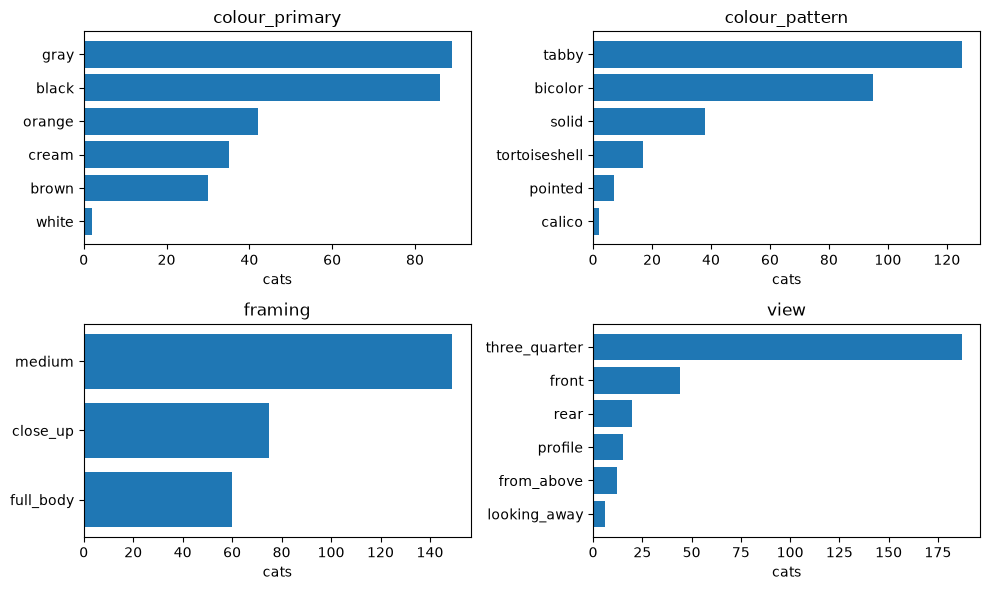

In [3]:
def counts(column):
    series = cats[column].fillna("(blank)").value_counts()
    series.index.name = None
    return series

for column in ("colour_primary", "colour_pattern", "breed", "framing", "view", "eyes", "eyes_colour"):
    print(f"\n{column}")
    print(counts(column).to_string())

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, column in zip(axes.ravel(), ("colour_primary", "colour_pattern", "framing", "view")):
    series = counts(column)
    ax.barh(series.index[::-1], series.to_numpy()[::-1], color="C0")
    ax.set_xlabel("cats")
    ax.set_title(column)
fig.tight_layout()
fig.savefig(FIG_DIR / "label_counts.png", bbox_inches="tight")
plt.show()

## Agreement across a cat's photos

Breed and eye state are the same label on nearly every photo of a cat. That is mostly because those labels have one dominant class. Camera angle agrees about half the time, so framing and view are a weak summary of the cat.

,breed_agreement,eyes_agreement,eyes_colour_agreement,camera_agreement
count,284.000,284.000,284.000,284.000
mean,0.938,0.910,0.712,0.508
std,0.133,0.126,0.214,0.173
min,0.423,0.506,0.312,0.196
25%,1.000,0.849,0.521,0.376
50%,1.000,1.000,0.690,0.472
75%,1.000,1.000,0.881,0.605
max,1.000,1.000,1.000,1.000


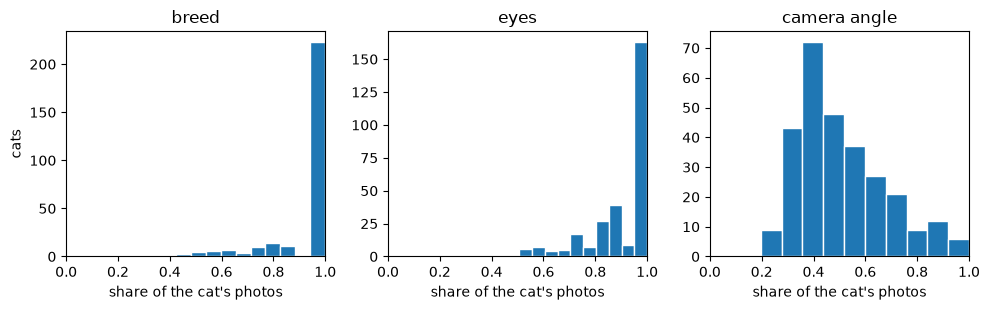

In [4]:
agreement = cats[["breed_agreement", "eyes_agreement", "eyes_colour_agreement", "camera_agreement"]].describe().round(3)
display(agreement)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, column, title in zip(
    axes,
    ("breed_agreement", "eyes_agreement", "camera_agreement"),
    ("breed", "eyes", "camera angle"),
):
    ax.hist(cats[column], bins=10, color="C0", edgecolor="white")
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of the cat's photos")
    ax.set_title(title)
axes[0].set_ylabel("cats")
fig.tight_layout()
fig.savefig(FIG_DIR / "label_agreement.png", bbox_inches="tight")
plt.show()

## Fur colour and strength

The next tables use the 237 cats with a fitted strength. Mean strength is zero by construction. A win rate is wins divided by appearances, pooled inside the label.

,cats,appearances,wins,mean_strength,win_rate
colour_primary,,,,,
brown,27,5035.0,2805.0,0.317,0.557
orange,35,6573.0,3491.0,0.195,0.531
gray,72,13211.0,6991.0,0.170,0.529
cream,31,5782.0,2880.0,-0.002,0.498
white,2,355.0,172.0,-0.107,0.485
black,70,12830.0,5554.0,-0.390,0.433


,cats,appearances,wins,mean_strength,win_rate
colour_pattern,,,,,
calico,2,391.0,210.0,0.268,0.537
tabby,101,18784.0,10095.0,0.216,0.537
tortoiseshell,17,3176.0,1588.0,0.011,0.500
bicolor,76,13936.0,6886.0,-0.046,0.494
pointed,7,1318.0,622.0,-0.098,0.472
solid,34,6181.0,2492.0,-0.540,0.403


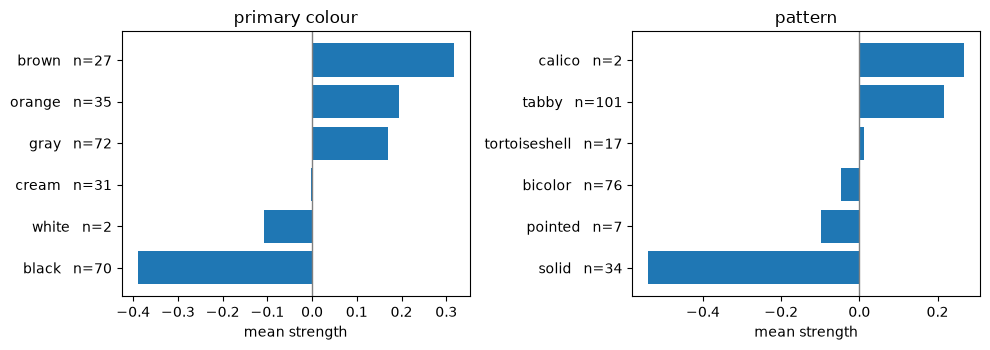

In [5]:
fit = cats.dropna(subset=["strength"]).copy()

def strength_by(frame, column):
    grouped = (
        frame.groupby(column, dropna=False)
        .agg(
            cats=("cat", "size"),
            appearances=("appearances", "sum"),
            wins=("wins", "sum"),
            mean_strength=("strength", "mean"),
        )
    )
    grouped["win_rate"] = grouped["wins"] / grouped["appearances"]
    return grouped.sort_values("mean_strength", ascending=False)

colour = strength_by(fit, "colour_primary")
pattern = strength_by(fit, "colour_pattern")
display(colour.round(3))
display(pattern.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, table, title in (
    (axes[0], colour, "primary colour"),
    (axes[1], pattern, "pattern"),
):
    ordered = table.sort_values("mean_strength")
    labels = [f"{name}   n={int(row.cats)}" for name, row in ordered.iterrows()]
    ax.barh(labels, ordered["mean_strength"], color="C0")
    ax.axvline(0, color="0.5", lw=1)
    ax.set_xlabel("mean strength")
    ax.set_title(title)
fig.tight_layout()
fig.savefig(FIG_DIR / "strength_by_fur_colour.png", bbox_inches="tight")
plt.show()

## Black share

`share_black` is the average share of black pixels inside the cat, across that cat's photos. Primary colour already says "black" or not. The share keeps the amount.

black primary: n=70  mean strength -0.390
other primary: n=167  mean strength 0.164
correlation of share_black with strength: -0.501    r² 0.251


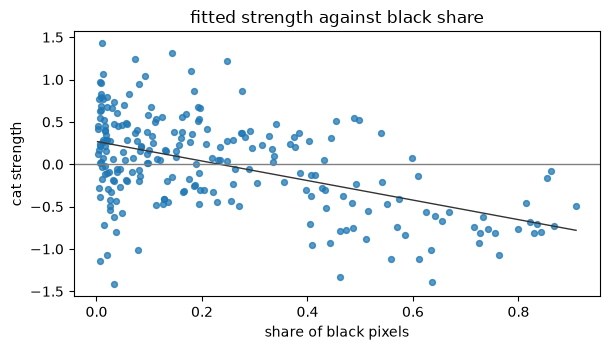

In [6]:
black = fit["colour_primary"].eq("black")
print(f"black primary: n={int(black.sum())}  mean strength {fit.loc[black, 'strength'].mean():.3f}")
print(f"other primary: n={int((~black).sum())}  mean strength {fit.loc[~black, 'strength'].mean():.3f}")
r = float(fit["share_black"].corr(fit["strength"]))
print(f"correlation of share_black with strength: {r:.3f}    r² {r ** 2:.3f}")

slope, intercept = np.polyfit(fit["share_black"], fit["strength"], 1)
x = np.linspace(fit["share_black"].min(), fit["share_black"].max(), 50)

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.scatter(fit["share_black"], fit["strength"], s=18, alpha=0.75, color="C0")
ax.plot(x, intercept + slope * x, color="0.2", lw=1)
ax.axhline(0, color="0.5", lw=1)
ax.set_xlabel("share of black pixels")
ax.set_ylabel("cat strength")
ax.set_title("fitted strength against black share")
fig.tight_layout()
fig.savefig(FIG_DIR / "strength_vs_black_share.png", bbox_inches="tight")
plt.show()

## Solid fur is mostly black

The low mean for `solid` is not a second finding. Almost every solid cat is also black. Inside bicolor cats, where both black and other primaries occur, the black cats are still lower.

In [7]:
print("fitted cats, primary black by pattern")
print(pd.crosstab(fit["colour_primary"].eq("black").rename("black"), fit["colour_pattern"]))

bicolor = fit[fit["colour_pattern"].eq("bicolor")]
print("\nbicolor only")
display(strength_by(bicolor, "colour_primary").round(3))

fitted cats, primary black by pattern
colour_pattern  bicolor  calico  pointed  solid  tabby  tortoiseshell
black                                                                
False                41       2        7      2    101             14
True                 35       0        0     32      0              3

bicolor only


,cats,appearances,wins,mean_strength,win_rate
colour_primary,,,,,
gray,11,1927.0,1066.0,0.293,0.553
orange,5,916.0,505.0,0.267,0.551
cream,23,4299.0,2186.0,0.042,0.508
white,2,355.0,172.0,-0.107,0.485
black,35,6439.0,2957.0,-0.251,0.459


## Pose, eyes, and breed

Framing and view sit on zero. Eye state is `both_open` for almost every cat. Breed is `domestic_shorthair` for 216 of the 237 fitted cats, so the other breed means are a few cats each. Eye colour follows the fur colour: most orange cats are labelled copper, and the copper advantage shrinks once primary colour is held fixed.

In [8]:
for column in ("framing", "view", "eyes"):
    print(f"\n{column}")
    display(strength_by(fit, column).round(3))

print("\neyes colour within primary colour")
within = (
    fit.groupby(["colour_primary", "eyes_colour"])
    .agg(cats=("cat", "size"), mean_strength=("strength", "mean"))
    .reset_index()
)
display(within.round(3))


framing


,cats,appearances,wins,mean_strength,win_rate
framing,,,,,
close_up,61,11231.0,5686.0,0.023,0.506
medium,127,23509.0,11710.0,-0.006,0.498
full_body,49,9046.0,4497.0,-0.013,0.497



view


,cats,appearances,wins,mean_strength,win_rate
view,,,,,
profile,15,2704.0,1360.0,0.058,0.503
from_above,8,1480.0,747.0,0.045,0.505
front,39,7158.0,3636.0,0.030,0.508
three_quarter,154,28561.0,14255.0,-0.007,0.499
looking_away,4,746.0,373.0,-0.036,0.500
rear,17,3137.0,1522.0,-0.068,0.485



eyes


,cats,appearances,wins,mean_strength,win_rate
eyes,,,,,
half_closed,7,1218.0,640.0,0.184,0.525
both_open,230,42568.0,21253.0,-0.006,0.499



eyes colour within primary colour


,colour_primary,eyes_colour,cats,mean_strength
0,black,blue,19,-0.287
1,black,copper,10,-0.129
2,black,green,2,-0.682
3,black,yellow,39,-0.492
4,brown,blue,2,0.117
5,brown,copper,15,0.438
6,brown,yellow,10,0.174
7,cream,blue,5,0.046
8,cream,copper,12,0.056
9,cream,green,2,-0.068


## What this is

Blacker fur goes with a lower strength. Cats labelled black average about −0.39, against about +0.16 for the other primary colours, and the correlation of black-pixel share with strength is about −0.50. The same direction shows up inside bicolor cats. Pose does not. These labels were not used to fit the strengths, and this notebook does not put them into the choice model.